In [2]:
# Student Performance Prediction
# Project developed for Avgova AI/ML Internship
print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")
print("Welcome to our Machine Learning Project!")
print("Our goal is to predict student academic performance.")



STUDENT PERFORMANCE PREDICTION
--------------------------------
Welcome to our Machine Learning Project!
Our goal is to predict student academic performance.


In [3]:
import pandas as pd

# Load student dataset
data = pd.read_csv(
    "../dataset/student-mat.csv",
    sep=";"
)

# Display first 5 records
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# Check dataset information
print("Dataset Shape:", data.shape)

print("\nDataset Information:")
data.info()

Dataset Shape: (395, 33)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nur

In [5]:
print("Missing Values:")
print(data.isnull().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [6]:
data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


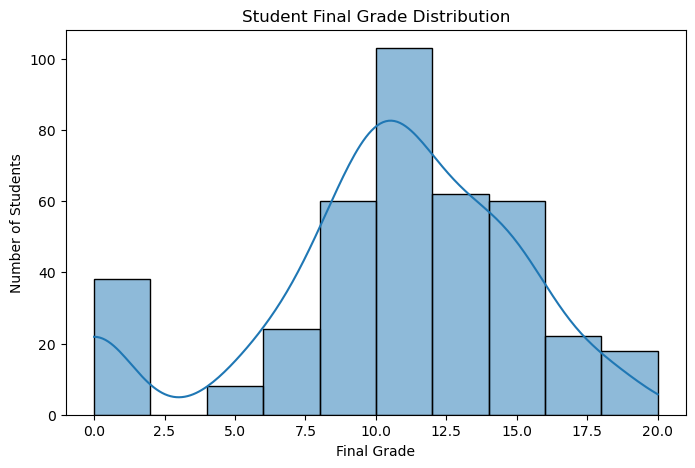

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Student final grade distribution
plt.figure(figsize=(8,5))
sns.histplot(data['G3'], bins=10, kde=True)

plt.title("Student Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()

In [8]:
# Import required libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Separate input and output
X = data.drop('G3', axis=1)
y = data['G3']

# Convert categorical data into numerical data
X = pd.get_dummies(X, drop_first=True)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Create Machine Learning model
model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Training data: (316, 41)
Testing data: (79, 41)
Model Training Completed Successfully!


In [9]:
# Predict student grades
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Absolute Error: 1.1645569620253164
R2 Score: 0.8147911386865877


In [10]:
# Compare actual and predicted student grades

import pandas as pd
import numpy as np

comparison = pd.DataFrame({
    "Actual Grades": np.array(y_test).ravel(),
    "Predicted Grades": np.array(y_pred).ravel()
})

print(comparison.head(10))

   Actual Grades  Predicted Grades
0             10              8.32
1             12             11.78
2              5              6.50
3             10              9.76
4              9              8.80
5             13             12.86
6             18             18.70
7              6              6.72
8              0              6.68
9             14             13.33


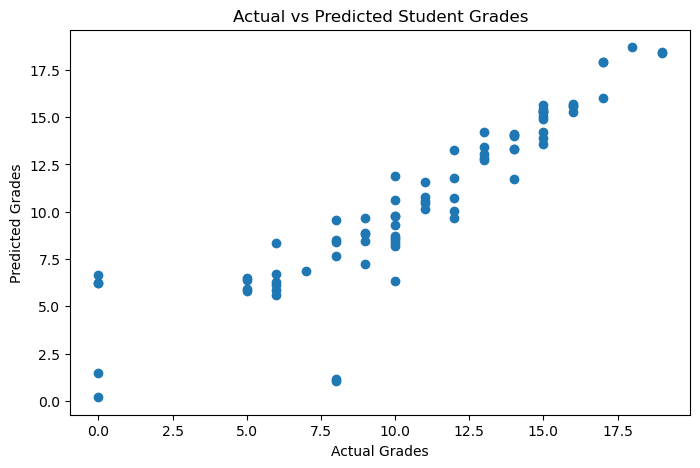

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Student Grades")

plt.show()

In [12]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
# Display all input features
print("Total Features:", len(X_train.columns))

print("\nFeature Names:")
for i, column in enumerate(X_train.columns, 1):
    print(i, column)

# Display sample student data
print("\nSample Student Data:")
print(X_train.head(3))

Total Features: 41

Feature Names:
1 age
2 Medu
3 Fedu
4 traveltime
5 studytime
6 failures
7 famrel
8 freetime
9 goout
10 Dalc
11 Walc
12 health
13 absences
14 G1
15 G2
16 school_MS
17 sex_M
18 address_U
19 famsize_LE3
20 Pstatus_T
21 Mjob_health
22 Mjob_other
23 Mjob_services
24 Mjob_teacher
25 Fjob_health
26 Fjob_other
27 Fjob_services
28 Fjob_teacher
29 reason_home
30 reason_other
31 reason_reputation
32 guardian_mother
33 guardian_other
34 schoolsup_yes
35 famsup_yes
36 paid_yes
37 activities_yes
38 nursery_yes
39 higher_yes
40 internet_yes
41 romantic_yes

Sample Student Data:
     age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  \
181   16     3     3           1          2         0       4         2   
194   16     2     3           2          1         0       5         3   
173   16     1     3           1          2         3       4         3   

     goout  Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  \
181      3     1  ...             Tru

In [14]:
# Load the saved machine learning model

import joblib

loaded_model = joblib.load("student_performance_model.pkl")

# Select one student from testing data
student = X_test.iloc[[0]]

# Predict the student's grade
prediction = loaded_model.predict(student)

# Display the result
print("Student Performance Prediction")
print("--------------------------------")
print("Predicted Grade:", prediction[0])
print("Actual Grade:", y_test.iloc[0] if hasattr(y_test, "iloc") else y_test[0])

print("\nPrediction completed successfully!")

Student Performance Prediction
--------------------------------
Predicted Grade: 8.32
Actual Grade: 10

Prediction completed successfully!


In [15]:
# Display all 41 input features clearly

for i, feature in enumerate(X_train.columns, 1):
    print(str(i) + ". " + feature)

print("\nTotal Features:", len(X_train.columns))

1. age
2. Medu
3. Fedu
4. traveltime
5. studytime
6. failures
7. famrel
8. freetime
9. goout
10. Dalc
11. Walc
12. health
13. absences
14. G1
15. G2
16. school_MS
17. sex_M
18. address_U
19. famsize_LE3
20. Pstatus_T
21. Mjob_health
22. Mjob_other
23. Mjob_services
24. Mjob_teacher
25. Fjob_health
26. Fjob_other
27. Fjob_services
28. Fjob_teacher
29. reason_home
30. reason_other
31. reason_reputation
32. guardian_mother
33. guardian_other
34. schoolsup_yes
35. famsup_yes
36. paid_yes
37. activities_yes
38. nursery_yes
39. higher_yes
40. internet_yes
41. romantic_yes

Total Features: 41


In [16]:
# STUDENT PERFORMANCE PREDICTION SYSTEM

import pandas as pd
import joblib

# Load saved model
loaded_model = joblib.load("student_performance_model.pkl")

# Create a sample student using existing encoded features
new_student = X_train.iloc[[0]].copy()

print("====================================")
print(" STUDENT PERFORMANCE PREDICTION")
print("====================================")

# Enter new student details
new_student["age"] = int(input("Enter student age: "))
new_student["Medu"] = int(input("Mother's education (0-4): "))
new_student["Fedu"] = int(input("Father's education (0-4): "))
new_student["studytime"] = int(input("Weekly study time (1-4): "))
new_student["failures"] = int(input("Number of past failures (0-3): "))
new_student["absences"] = int(input("Number of absences: "))
new_student["G1"] = int(input("First period grade (0-20): "))
new_student["G2"] = int(input("Second period grade (0-20): "))

# Predict performance
prediction = loaded_model.predict(new_student)

print("\n====================================")
print("       PREDICTION RESULT")
print("====================================")

print("Predicted Final Grade:", round(float(prediction[0]), 2))

if prediction[0] >= 15:
    print("Performance: Excellent")
elif prediction[0] >= 10:
    print("Performance: Good")
else:
    print("Performance: Needs Improvement")

print("====================================")

 STUDENT PERFORMANCE PREDICTION


Enter student age:  16
Mother's education (0-4):  3
Father's education (0-4):  2
Weekly study time (1-4):  3
Number of past failures (0-3):  0
Number of absences:  2
First period grade (0-20):  12
Second period grade (0-20):  14



       PREDICTION RESULT
Predicted Final Grade: 14.13
Performance: Good


In [18]:
print("Machine Learning Algorithm:")
print(type(model).__name__)

Machine Learning Algorithm:
RandomForestRegressor
